# Bayesian estimation of FvCB photosynthetic parameters with JAGS — reproduction

Reproduction of **Xiao Y., Sloan J., Hepworth C., Osborne C. P., Fleming A. J., Chen X.-Y., Zhu X.-G. (2021)
"Estimating uncertainty: A Bayesian approach to modelling photosynthesis in C3 leaves",
*Plant, Cell & Environment* 44(5):1436–1450.** [DOI 10.1111/pce.13995](https://doi.org/10.1111/pce.13995)

**Author tool (run here nearly verbatim):** [`yixiao2/FvCB-JAGS`](https://github.com/yixiao2/FvCB-JAGS)
@ commit `bb216d78000bda79298ddcd3e6ee60e59254bc14` (version 1, 2019-09-21, GPL-3.0). The authors' released R/JAGS notebook
`FvCB_JAGS.ipynb` and its `src/` code are downloaded from the pinned commit at runtime and executed
by this notebook via `Rscript`; their R code cells are **not rewritten**.

**Scope:** run the authors' own Bayesian estimation workflow on their bundled experimental demo data
`data/expdata0827.csv` (rice, cultivar IR64; 4 replications of concurrent An–Ci and Y(II)–Ci curves at
PPFD 2000/300/200/100 µmol m⁻² s⁻¹), with Km fixed at 428 µbar (rice value, von Caemmerer 2000), producing
posterior distributions of Vcmax, J, Resp, Gstar, rm, s and posterior-predicted response curves.

**Execution status:** executed on a Google Colab **CPU** runtime (no GPU is used anywhere in this
method — it is an MCMC sampling task). See the validation record at the end of the notebook.

**AI-orchestration disclosure / AIによるオーケストレーションの注記:**
The scientific R code (FvCB model, JAGS model file, MCMC settings, plotting) is the authors' own,
executed verbatim from the pinned commit. This Colab wrapper (system setup, downloads, Rscript
launching, figure display) is AI-added and was not authored or endorsed by the paper's authors.
A single-example run does not verify the paper's dataset-level conclusions.

**Expected duration:** roughly 10–20 minutes end to end on the free CPU runtime
(R/JAGS install ~2–4 min; MCMC 3 chains × 20,000 iterations × 5 fits; posterior-curve plotting).
Downloads: R/JAGS apt packages plus a few MB from GitHub.

日本語: 本ノートブックは、Xiao ら (2021, Plant Cell & Environment) のベイズ法による FvCB 光合成
パラメータ推定ツール（JAGS）を、著者公開の R コードを pinned commit からそのまま実行して再現します。
デモデータ（イネ IR64、4 反復の An–Ci / Y(II)–Ci 同時測定）を用い、Km を 428 µbar に固定して
Vcmax・J・Resp・Gstar・rm・s の事後分布と予測応答曲線を得ます。GPU は不要で、CPU ランタイムで
約 10–20 分です。R の科学コードは著者原文のまま実行され、Colab 実行用のラッパーのみ AI が追加しました。

## 0. Runtime selection and Run all

Select **Runtime → Change runtime type → CPU** (default standard CPU is sufficient; no GPU needed).
Then **Runtime → Run all**. All downloads (R, JAGS, author code, demo data) happen inside this
notebook; nothing is read from your Drive.

日本語: ランタイムは CPU を選択してください（GPU 不要）。「ランタイム → すべてのセルを実行」で
R・JAGS・著者コード・デモデータの取得から実行まですべてこのノートブック内で完結します。

In [ ]:
import os, platform, sys
print("Python:", sys.version.split()[0], "|", platform.machine())
print("CPUs:", os.cpu_count())
assert sys.version_info >= (3, 8)

Python: 3.13.18 | x86_64
CPUs: 2


**Step 1 — Install R and JAGS (system packages).** `r-base` provides R, `jags` provides the
Just Another Gibbs Sampler used by the paper, and `r-cran-rjags` is the R link library.
Expected result: R ≥ 4.x and JAGS 4.x installed on the Colab VM. 日本語: apt で R・JAGS・rjags を導入します。

In [ ]:
import subprocess
r = subprocess.run(["apt-get", "install", "-y", "-qq", "r-base", "jags", "r-cran-rjags"],
                   capture_output=True, text=True, timeout=1800)
print("apt rc =", r.returncode)
if r.returncode != 0:
    print(r.stdout[-2000:]); print(r.stderr[-2000:]); raise RuntimeError("apt install failed")
print(subprocess.run(["R", "--version"], capture_output=True, text=True).stdout.splitlines()[0])
print(subprocess.run(["jags", "--version"], capture_output=True, text=True).stdout.strip())

apt rc = 0
R version 4.6.1 (2026-06-24) -- "Happy Hop"



**Step 2 — Install the R packages the author notebook loads.** The author's first cell sources
`src/FunJAGSFvCB.R` and loads `coda`, `R2jags`, `lattice`, `viridis`, `MASS` and `RColorBrewer`.
We preinstall them from CRAN so the verbatim author cells run unchanged. Expected result: package
versions printed. 日本語: 著者ノートブックが必要とする R パッケージを CRAN から導入します。

In [ ]:
import subprocess
script = r'''
options(repos = c(CRAN = "https://cloud.r-project.org"), timeout = 900)
install.packages(c("coda", "rjags", "R2jags", "lattice", "viridis", "MASS", "RColorBrewer"))
for (p in c("coda", "rjags", "R2jags", "lattice", "viridis", "MASS", "RColorBrewer"))
    cat(p, as.character(packageVersion(p)), "\n")
'''
r = subprocess.run(["Rscript", "-"], input=script, capture_output=True, text=True, timeout=2400)
print("Rscript rc =", r.returncode)
print(r.stdout[-1500:]); print(r.stderr[-500:])
if r.returncode != 0: raise RuntimeError("R package install failed")

Rscript rc = 0
r-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c init.c -o init.o
x86_64-linux-gnu-g++ -std=gnu++20 -I"/usr/share/R/include" -DNDEBUG -I/usr/include/JAGS        -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3   -c jags.cc -o jags.o
x86_64-linux-gnu-g++ -std=gnu++20 -I"/usr/share/R/include" -DNDEBUG -I/usr/include/JAGS        -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protect

**Step 3 — Fetch the pinned author code and demo data.** Everything is downloaded from the
pinned commit `bb216d78000bda79298ddcd3e6ee60e59254bc14` of `yixiao2/FvCB-JAGS` and verified against the GitHub tree blob SHA-1s
(git blob hashing: `sha1("blob <size>\0" + bytes)`). Files are laid out as in the author repository so
the verbatim cells' relative paths (`./data/...`, `./src/...`, `./output/...`) resolve.
The two demo CSVs are dataset bytes and are only ever handled here on the Colab VM.
日本語: pinned commit から著者のコード・JAGS モデル・デモデータを取得し blob SHA-1 で検証します。

In [ ]:
import hashlib, pathlib, urllib.request

REPO = "yixiao2/FvCB-JAGS"; COMMIT = "bb216d78000bda79298ddcd3e6ee60e59254bc14"; RAW = "https://raw.githubusercontent.com/yixiao2/FvCB-JAGS/bb216d78000bda79298ddcd3e6ee60e59254bc14"
# (git-blob SHA-1 from the GitHub tree at the pinned commit, expected size in bytes)
EXPECTED = {
    "FvCB_JAGS.ipynb": ("c4602b4a5be15145aa8b7e4d9f42a1bff0d4eff6", 1325919),
    "src/FunJAGSFvCB.R": ("c2adf9cdb82f106495b6981659ce9363cbdd659a", 5409),
    "src/fvcb_ayii_ciLL_gm_fixKm_vR.txt": ("79e2114d5bc5553c7d7b65705f49ca8c75d70980", 1466),
    "data/expdata0827.csv": ("16936f0199a053c91b00a7357313c6ab54beaad0", 4793),
    "data/syntheticdata0827.csv": ("b64a9f7021fe4581976aade275b38a4789a5beb1", 5915),
    "data/readme_data.txt": ("f4bd4dae18280f27b248fbfdeb5d1b434ac63b24", 160),
}
def git_blob_sha(b): return hashlib.sha1(b"blob %d\x00" % len(b) + b).hexdigest()

base = pathlib.Path("/content/FvCB-JAGS"); base.mkdir(exist_ok=True)
results = {}
for rel, (sha, size) in EXPECTED.items():
    dest = base / rel; dest.parent.mkdir(parents=True, exist_ok=True)
    data = urllib.request.urlopen(f"{RAW}/{rel}", timeout=180).read()
    digest, ok = git_blob_sha(data), (git_blob_sha(data) == sha and len(data) == size)
    dest.write_bytes(data)
    results[rel] = ok
    print(f"{rel}: {len(data)} B blob_sha1={digest[:12]} verified={ok}")
assert all(results.values()), results
print("All pinned author files verified.")

FvCB_JAGS.ipynb: 1325919 B blob_sha1=c4602b4a5be1 verified=True
src/FunJAGSFvCB.R: 5409 B blob_sha1=c2adf9cdb82f verified=True


src/fvcb_ayii_ciLL_gm_fixKm_vR.txt: 1466 B blob_sha1=79e2114d5bc5 verified=True
data/expdata0827.csv: 4793 B blob_sha1=16936f0199a0 verified=True


data/syntheticdata0827.csv: 5915 B blob_sha1=b64a9f7021fe verified=True
data/readme_data.txt: 160 B blob_sha1=f4bd4dae1828 verified=True
All pinned author files verified.


## Input preview (before any estimation)

**Demo data check.** The experimental demo `expdata0827.csv` stores, for each of the 4 replications,
four rows (Ci, PPFD, An, Y(II)) over up to 28 measured points. We show its shape, the light levels
detected per replication, and a small An–Ci / Y(II)–Ci scatter at saturating light (2000 µmol m⁻² s⁻¹)
so the actual input is visible before the Bayesian fit. The scatter is an additional visualization
created for this notebook, not an author figure. 日本語: 推定前にデモデータの構成と飽和光下の
An–Ci・Y(II)–Ci 散布図を確認します（本ノートブック独自の補助図）。

shape: (16, 29)
row labels: ['Ci(umol)', 'PPFD', 'An', 'PhiPSII', 'Ci(umol)', 'PPFD', 'An', 'PhiPSII', 'Ci(umol)', 'PPFD', 'An', 'PhiPSII', 'Ci(umol)', 'PPFD', 'An', 'PhiPSII']
rep 1: PPFD levels = [np.float64(100.0), np.float64(200.0), np.float64(300.0), np.float64(2000.0)]
rep 2: PPFD levels = [np.float64(100.0), np.float64(200.0), np.float64(300.0), np.float64(2000.0)]
rep 3: PPFD levels = [np.float64(100.0), np.float64(200.0), np.float64(300.0), np.float64(2000.0)]
rep 4: PPFD levels = [np.float64(100.0), np.float64(200.0), np.float64(300.0), np.float64(2000.0)]


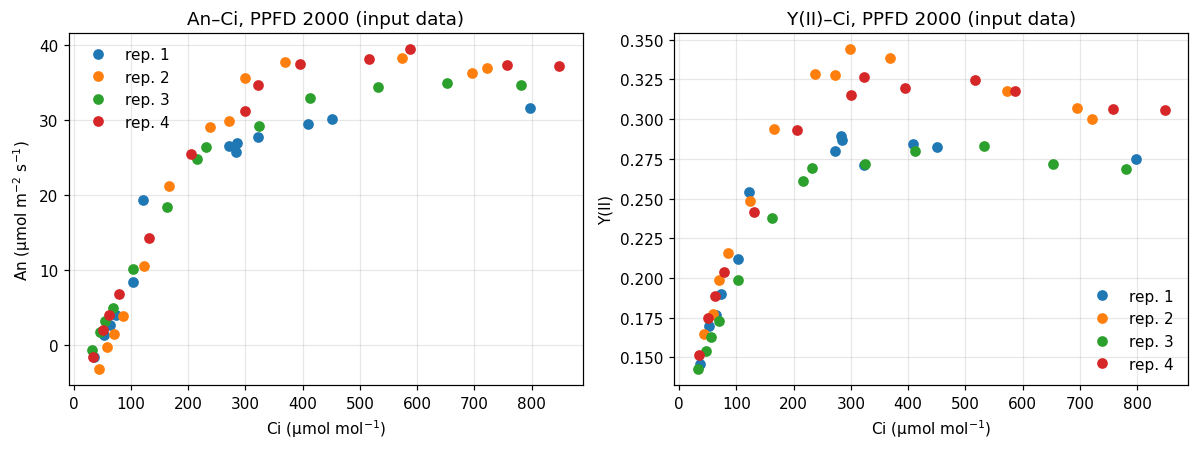

Rows are Ci/PPFD/An/Y(II) per replication; columns are measured points (NaN = not measured).


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/FvCB-JAGS/data/expdata0827.csv")
print("shape:", df.shape)
vals = df.iloc[:, 1:].to_numpy(dtype=float)
labels = df["Unnamed: 0"].tolist()
print("row labels:", labels)
nrep, rows_per_rep = 4, 4
for rep in range(nrep):
    q = vals[rep * rows_per_rep + 1]
    print(f"rep {rep+1}: PPFD levels = {sorted(set(q[~pd.isna(q)]))}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=110)
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
for rep in range(nrep):
    ci, q, a, yii = (vals[rep * 4 + 0], vals[rep * 4 + 1], vals[rep * 4 + 2], vals[rep * 4 + 3])
    sat = q == 2000.0
    axes[0].plot(ci[sat], a[sat], "o", color=colors[rep], label=f"rep. {rep+1}")
    axes[1].plot(ci[sat], yii[sat], "o", color=colors[rep], label=f"rep. {rep+1}")
axes[0].set(xlabel="Ci (µmol mol$^{-1}$)", ylabel="An (µmol m$^{-2}$ s$^{-1}$)", title="An–Ci, PPFD 2000 (input data)")
axes[1].set(xlabel="Ci (µmol mol$^{-1}$)", ylabel="Y(II)", title="Y(II)–Ci, PPFD 2000 (input data)")
for ax in axes: ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("/content/input_preview.png"); plt.show()
print("Rows are Ci/PPFD/An/Y(II) per replication; columns are measured points (NaN = not measured).")

**Step 4 — Extract the author's code cells and run the released pipeline ("Run all").** The released
`FvCB_JAGS.ipynb` is read as JSON and all 16 of its R code cells are copied **verbatim** (each checked
against a distinctive marker from the pinned file) into one `run_author_pipeline.R` script — the
equivalent of the authors' "Cell → Run all" — and executed with a single `Rscript` process so all
state is shared, exactly as in the author's notebook kernel. Cell indices refer to the pinned file.

**One documented compatibility adaptation (wrapper-level, author lines untouched):** the authors'
figure cells end with `dev.copy(png/pdf, ...); dev.off()`, which relies on the display-list
recording that interactive R kernels provide. In a plain `Rscript` process the auto-opened device
does not record the display list, so those saves would produce empty/missing files. We therefore
open an explicit recording PDF device (`dev.control("enable")`) and reset it before each author
figure section, so each `dev.copy` replays exactly its own section's plots — verified on this VM.
Before running, the empty `output/` directory of the released repository is also recreated, because
the author's configuration cell creates its nested result subfolders without `recursive=TRUE` and the
repository ships `output/` itself. Expected result: light levels detected, JAGS runs for the 4
replications and all-replications fit (several minutes), summary CSV and all figure files written.
日本語: pinned ノートブックから著者の R コードセルをすべてそのまま抽出し、1 つの Rscript
プロセスで「Run all」相当として実行します（数分かかります）。非対話 R では dev.copy の保存のため
記録デバイスのラッパー（著者行は無変更）を併用します。

In [ ]:
import json, pathlib, subprocess

NB_PATH = "/content/FvCB-JAGS/FvCB_JAGS.ipynb"
nb = json.load(open(NB_PATH))
assert nb["metadata"]["kernelspec"]["name"] == "ir", "author notebook must be R-kernel"
by_index = {i: "".join(c["source"]) for i, c in enumerate(nb["cells"]) if c["cell_type"] == "code"}

# (cell index in pinned notebook, distinctive marker substring, reset device before cell?)
SPEC = [
    (3, "source('src/FunJAGSFvCB.R')", False),
    (6, "#  USER CONFIGURATION [1/3]  #", False),
    (7, "# load csv file of input data", False),
    (10, "# if there is only one replication, this step is skipped.", True),
    (12, "## plot each replication", True),
    (15, "#  USER CONFIGURATION [2/3]  #", False),
    (17, "#  USER CONFIGURATION [3/3]  #", False),
    (19, "# run JAGS with each replication as observation of Bayesian parameter estimation", False),
    (21, "# Print summary of JAGS results", False),
    (22, "# plot the Monte-Carlo-Markov-Chain of approximated posterior distributions", True),
    (25, "cmap3=brewer.pal(NumRep,", True),
    (27, "# to dev: let user select which parameters to plot the bivariate distribution", False),
    (28, "tmp.kde <- kde2d(xdata, ydata, n=50)", True),
    (30, "numsamples2plot <- 1000", False),
    (31, "cmap4 <- rainbow(length(PPFDdetected)-1)", True),
    (33, "## save notebook", False),
]
# AI-added wrapper (see markdown above): an explicit recording device is required so the
# authors' verbatim dev.copy(...); dev.off() saves work in non-interactive Rscript.
HEADER = '''options(warn = 1)
setwd("/content/FvCB-JAGS")
RESET_DEVICE <- function() {
    while (dev.cur() > 1) dev.off()
    pdf(file = "/content/FvCB-JAGS/recording.pdf", width = 9, height = 9)
    dev.control("enable")
}
RESET_DEVICE()
'''
parts = [HEADER]
for idx, marker, reset in SPEC:
    src = by_index[idx]
    assert marker in src, f"cell #{idx} lacks expected marker {marker!r}; got: {src[:80]!r}"
    if reset:
        parts.append("RESET_DEVICE()  # AI-added wrapper: isolate this author figure section")
    parts.append(f"# ===== FvCB_JAGS.ipynb code cell #{idx} (verbatim) =====\n{src}")
script = "\n\n".join(parts) + "\n"
pathlib.Path("/content/FvCB-JAGS/run_author_pipeline.R").write_text(script)
print(f"run_author_pipeline.R written from cells {[i for i, _, _ in SPEC]} ({len(script)} chars)")

# The released repository ships an output/ directory; the author's cell creates nested
# result subfolders with dir.create() non-recursively, so the parent must exist first.
pathlib.Path("/content/FvCB-JAGS/output").mkdir(exist_ok=True)

r = subprocess.run(["Rscript", "run_author_pipeline.R"], cwd="/content/FvCB-JAGS",
                   capture_output=True, text=True, timeout=5400)
print("---- R stdout (tail) ----"); print(r.stdout[-4000:])
print("---- R stderr (tail) ----"); print(r.stderr[-3000:])
if r.returncode != 0: raise RuntimeError(f"author pipeline failed, rc={r.returncode}")
print("Author pipeline completed.")

run_author_pipeline.R written from cells [3, 6, 7, 10, 12, 15, 17, 19, 21, 22, 25, 27, 28, 30, 31, 33] (29590 chars)


---- R stdout (tail) ----
0.436    0.870     2.531 1.007
s         0.305    0.012    0.282    0.297    0.304    0.313     0.328 1.008
taoA      0.240    0.074    0.116    0.187    0.233    0.285     0.407 1.004
taoyii 6032.244 1892.726 2912.376 4677.114 5835.314 7154.329 10304.319 1.001
       n.eff
Gstar    130
J[1]     260
J[2]     290
J[3]     290
J[4]     290
Km         1
Resp     400
Vcmax    120
rm       370
s        270
taoA     660
taoyii  4700

For each parameter, n.eff is a crude measure of effective sample size,
and Rhat is the potential scale reduction factor (at convergence, Rhat=1).




***********************************************
Summary of JAGS with replication No. 3 
***********************************************
Inference for Bugs model at "./src/fvcb_ayii_ciLL_gm_fixKm_vR.txt", fit using jags,
 3 chains, each with 20000 iterations (first 10000 discarded)
 n.sims = 30000 iterations saved. Running time = secs
         mu.vect  sd.vect      2.5%       25%       50% 

### Author figure: raw concurrent curves (s1.2)

The authors' own saved figure for all 4 replications: An–Ci and Y(II)–Ci at saturating light (top row)
and at the three low light levels (bottom row). Displayed unmodified from
`output/output_exp0827/allreps/s1.2-raw curves-allreps.png`.
日本語: 著者ノートブックが保存した生データ曲線図（4 反復、飽和光・低光）をそのまま表示します。

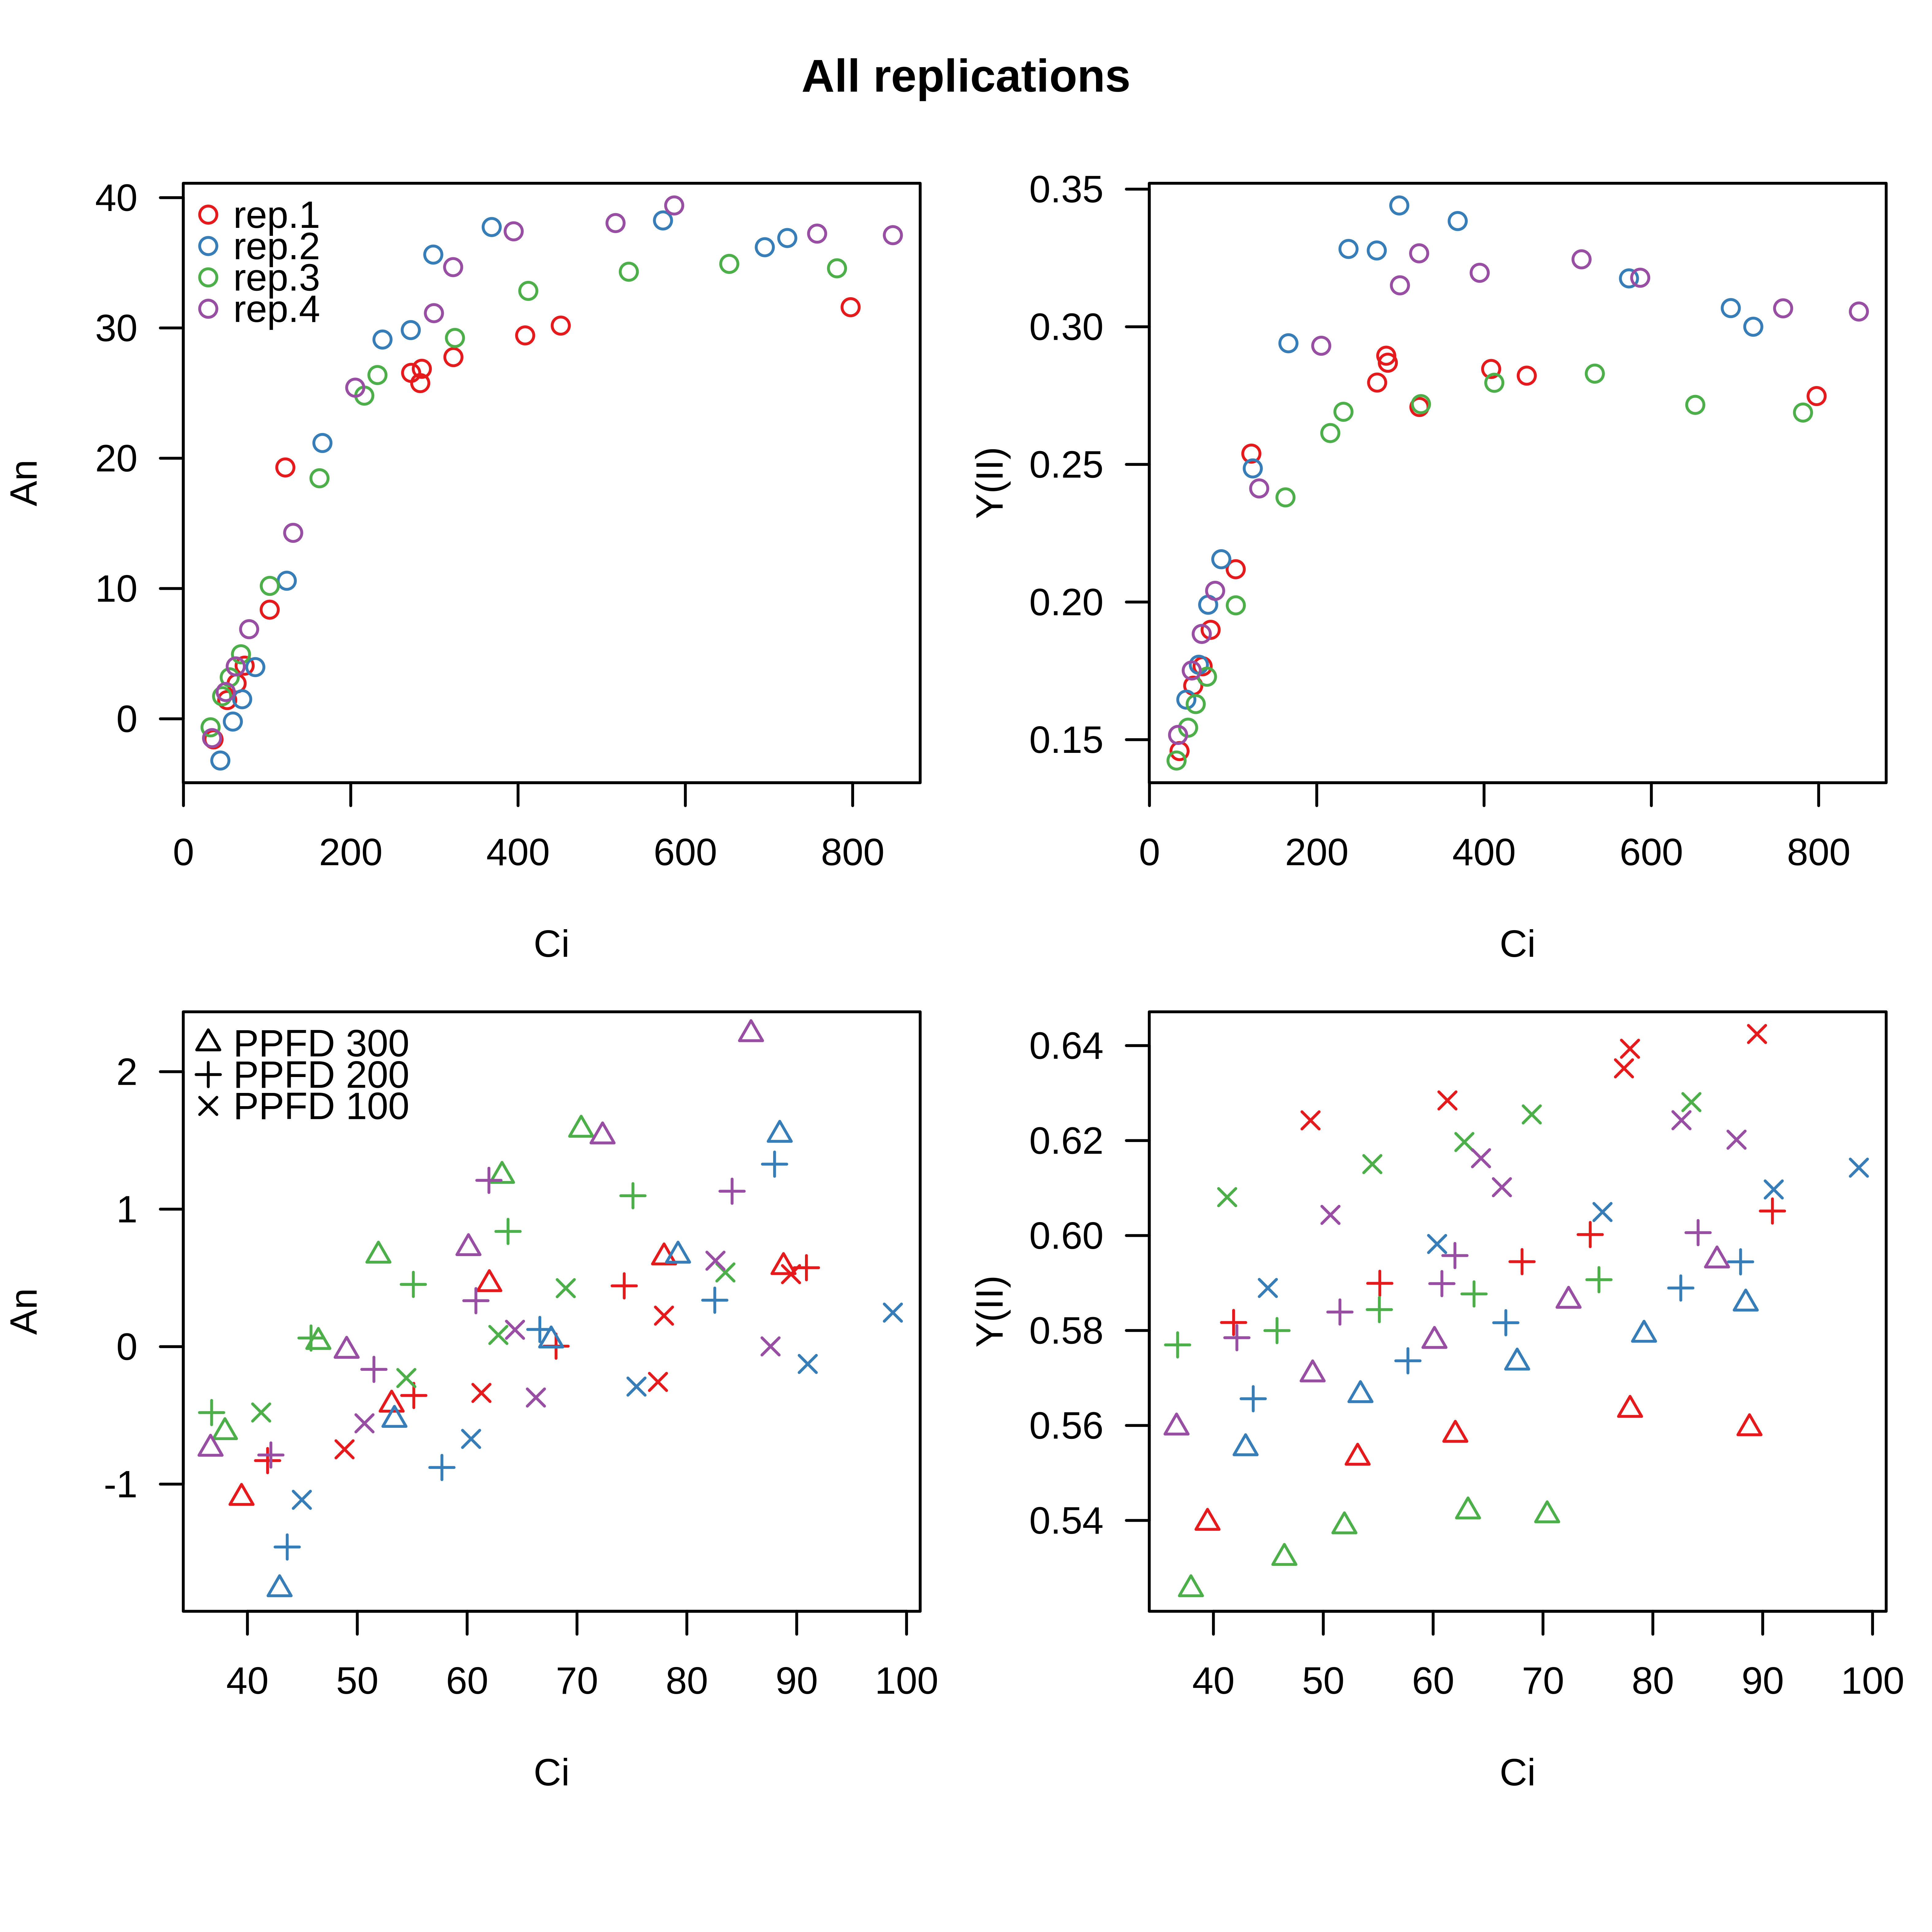

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/FvCB-JAGS/output/output_exp0827/allreps/s1.2-raw curves-allreps.png"))

### Posterior summary (author's s2.4 output)

**Posterior summary table.** The author-written `s2.4-summary JAGS results.csv` is parsed and shown
for the pooled fit ("all replications") and replication 1: mean, SD, 2.5%/50%/97.5% quantiles and
Rhat for Vcmax, J[1..4], Resp, Km, Gstar, rm, s. Rhat ≈ 1.00 (< 1.1) indicates the author's
convergence criterion is met. 日本語: 著者セルが書き出した要約 CSV（平均・SD・分位点・Rhat）を表示します。

In [ ]:
import pandas as pd, io, re
lines = open("/content/FvCB-JAGS/output/output_exp0827/s2.4-summary JAGS results.csv").read().splitlines()
sections, cur = {}, None
for ln in lines:
    m = re.match(r'^"Summary of JAGS with (.+)"$', ln.strip())
    if m:
        cur = m.group(1); sections[cur] = []
    elif cur is not None and ln.strip():
        sections[cur].append(ln)
tables = {k: pd.read_csv(io.StringIO("\n".join(v)), index_col=0) for k, v in sections.items()}
for name in ["all replications", "replication No.1"]:
    if name in tables:
        t = tables[name]
        print("==", name, "==")
        display(t[[c for c in ["mean", "sd", "2.5%", "50%", "97.5%", "Rhat"] if c in t.columns]])

== all replications ==


,mean,sd,2.5%,50%,97.5%,Rhat
Gstar,35.255775,2.621387,29.770432,35.435078,39.996285,1.005477
J[1],179.342621,2.779168,173.971491,179.331300,184.811704,1.007231
J[2],50.257048,1.062944,48.260061,50.245187,52.370157,1.008180
J[3],35.139226,0.738659,33.746895,35.126071,36.597870,1.008109
J[4],18.489747,0.386311,17.757510,18.484823,19.255374,1.008775
Km,428.000000,0.000000,428.000000,428.000000,428.000000,1.000000
Resp,1.663380,0.378051,0.967519,1.646019,2.455672,1.001598
Vcmax,101.062915,4.822546,94.102749,100.223678,112.868552,1.002448
rm,0.506503,0.405330,0.027483,0.408832,1.493252,1.001024
s,0.299211,0.005962,0.287991,0.299140,0.310944,1.009135


== replication No.1 ==


,mean,sd,2.5%,50%,97.5%,Rhat
Gstar,28.248305,3.884300,19.513295,28.433118,35.267085,1.002814
J[1],157.838026,4.521037,148.973986,157.841676,166.771142,1.006816
J[2],46.760512,1.526971,43.777025,46.755516,49.771910,1.008127
J[3],33.409049,1.084595,31.298165,33.408461,35.566229,1.008105
J[4],17.820586,0.578030,16.692950,17.823030,18.960844,1.008132
Km,428.000000,0.000000,428.000000,428.000000,428.000000,1.000000
Resp,2.672310,0.653751,1.484721,2.637111,4.070895,1.001746
Vcmax,107.291424,8.908169,95.288790,105.513311,130.363335,1.001941
rm,0.626577,0.590576,0.026169,0.452779,2.246982,1.001721
s,0.281068,0.008938,0.263568,0.281105,0.298721,1.008380


**Reference comparison against the authors' committed results.** The authors' repository ships
their own `output/output_exp0827/s2.4-summary JAGS results.csv` generated from this exact demo with
their notebook. We download that pinned reference file and compare posterior means/SDs with this
run's. Expected: near-identical values (same model, data and seed; small MCMC variation across
JAGS versions is acceptable). This is a reference check for the minimal example, not a verification
of the paper's dataset-level results. 日本語: 著者が公開している同デモの要約 CSV と本実行の
事後平均・SD を比較します（同じモデル・データ・シード値のためほぼ一致するはずです）。

In [ ]:
import pandas as pd, io, re, urllib.request

REF_URL = "https://raw.githubusercontent.com/yixiao2/FvCB-JAGS/bb216d78000bda79298ddcd3e6ee60e59254bc14/output/output_exp0827/s2.4-summary%20JAGS%20results.csv"
ref = urllib.request.urlopen(REF_URL, timeout=120).read().decode()
lines = ref.splitlines()
sections, cur = {}, None
for ln in lines:
    m = re.match(r'^"Summary of JAGS with (.+)"$', ln.strip())
    if m:
        cur = m.group(1); sections[cur] = []
    elif cur is not None and ln.strip():
        sections[cur].append(ln)
ref_all = pd.read_csv(io.StringIO("\n".join(sections["all replications"])), index_col=0)

ours = tables["all replications"]
cmp = pd.DataFrame({"mean_ours": ours["mean"], "mean_author": ref_all["mean"],
                     "sd_ours": ours["sd"], "sd_author": ref_all["sd"]})
cmp["abs_mean_diff"] = (cmp["mean_ours"] - cmp["mean_author"]).abs()
display(cmp)
print("Max |mean difference| (all-reps fit):", cmp["abs_mean_diff"].max())

,mean_ours,mean_author,sd_ours,sd_author,abs_mean_diff
Gstar,35.255775,35.448973,2.621387,2.656393,0.193198
J[1],179.342621,179.628196,2.779168,2.738944,0.285575
J[2],50.257048,50.372185,1.062944,1.041332,0.115137
J[3],35.139226,35.220942,0.738659,0.722106,0.081716
J[4],18.489747,18.530806,0.386311,0.379897,0.041059
Km,428.000000,428.000000,0.000000,0.000000,0.000000
Resp,1.663380,1.657853,0.378051,0.384998,0.005527
Vcmax,101.062915,100.988534,4.822546,4.934615,0.074381
rm,0.506503,0.490235,0.405330,0.405585,0.016268
s,0.299211,0.299871,0.005962,0.005835,0.000660


Max |mean difference| (all-reps fit): 0.28557457557300836


### Author figures: marginal posteriors and posterior-predicted curves (Step 3)

**What runs here:** nothing new — the previous cell already executed the authors' Step 3
(marginal posteriors s3.1, bivariate KDEs s3.2, and 1000-sample posterior predicted response curves
s3.3 via their closed-form FvCB solution `FunFvCBgmOPTAYII2ci`). The authors saved s3.3 as PDF; we
rasterize one page with poppler for display. Expected result: s3.1 PNG and rasterized s3.3 shown below.
日本語: 前セルで著者の Step 3（s3.1–s3.3）まで実行済みです。PDF で保存された s3.3 を poppler で
PNG 化して表示します。

poppler rc = 0


rasterized: /content/FvCB-JAGS/output/output_exp0827/rep1/s3.3-posterior Ci response curves-rep1.pdf


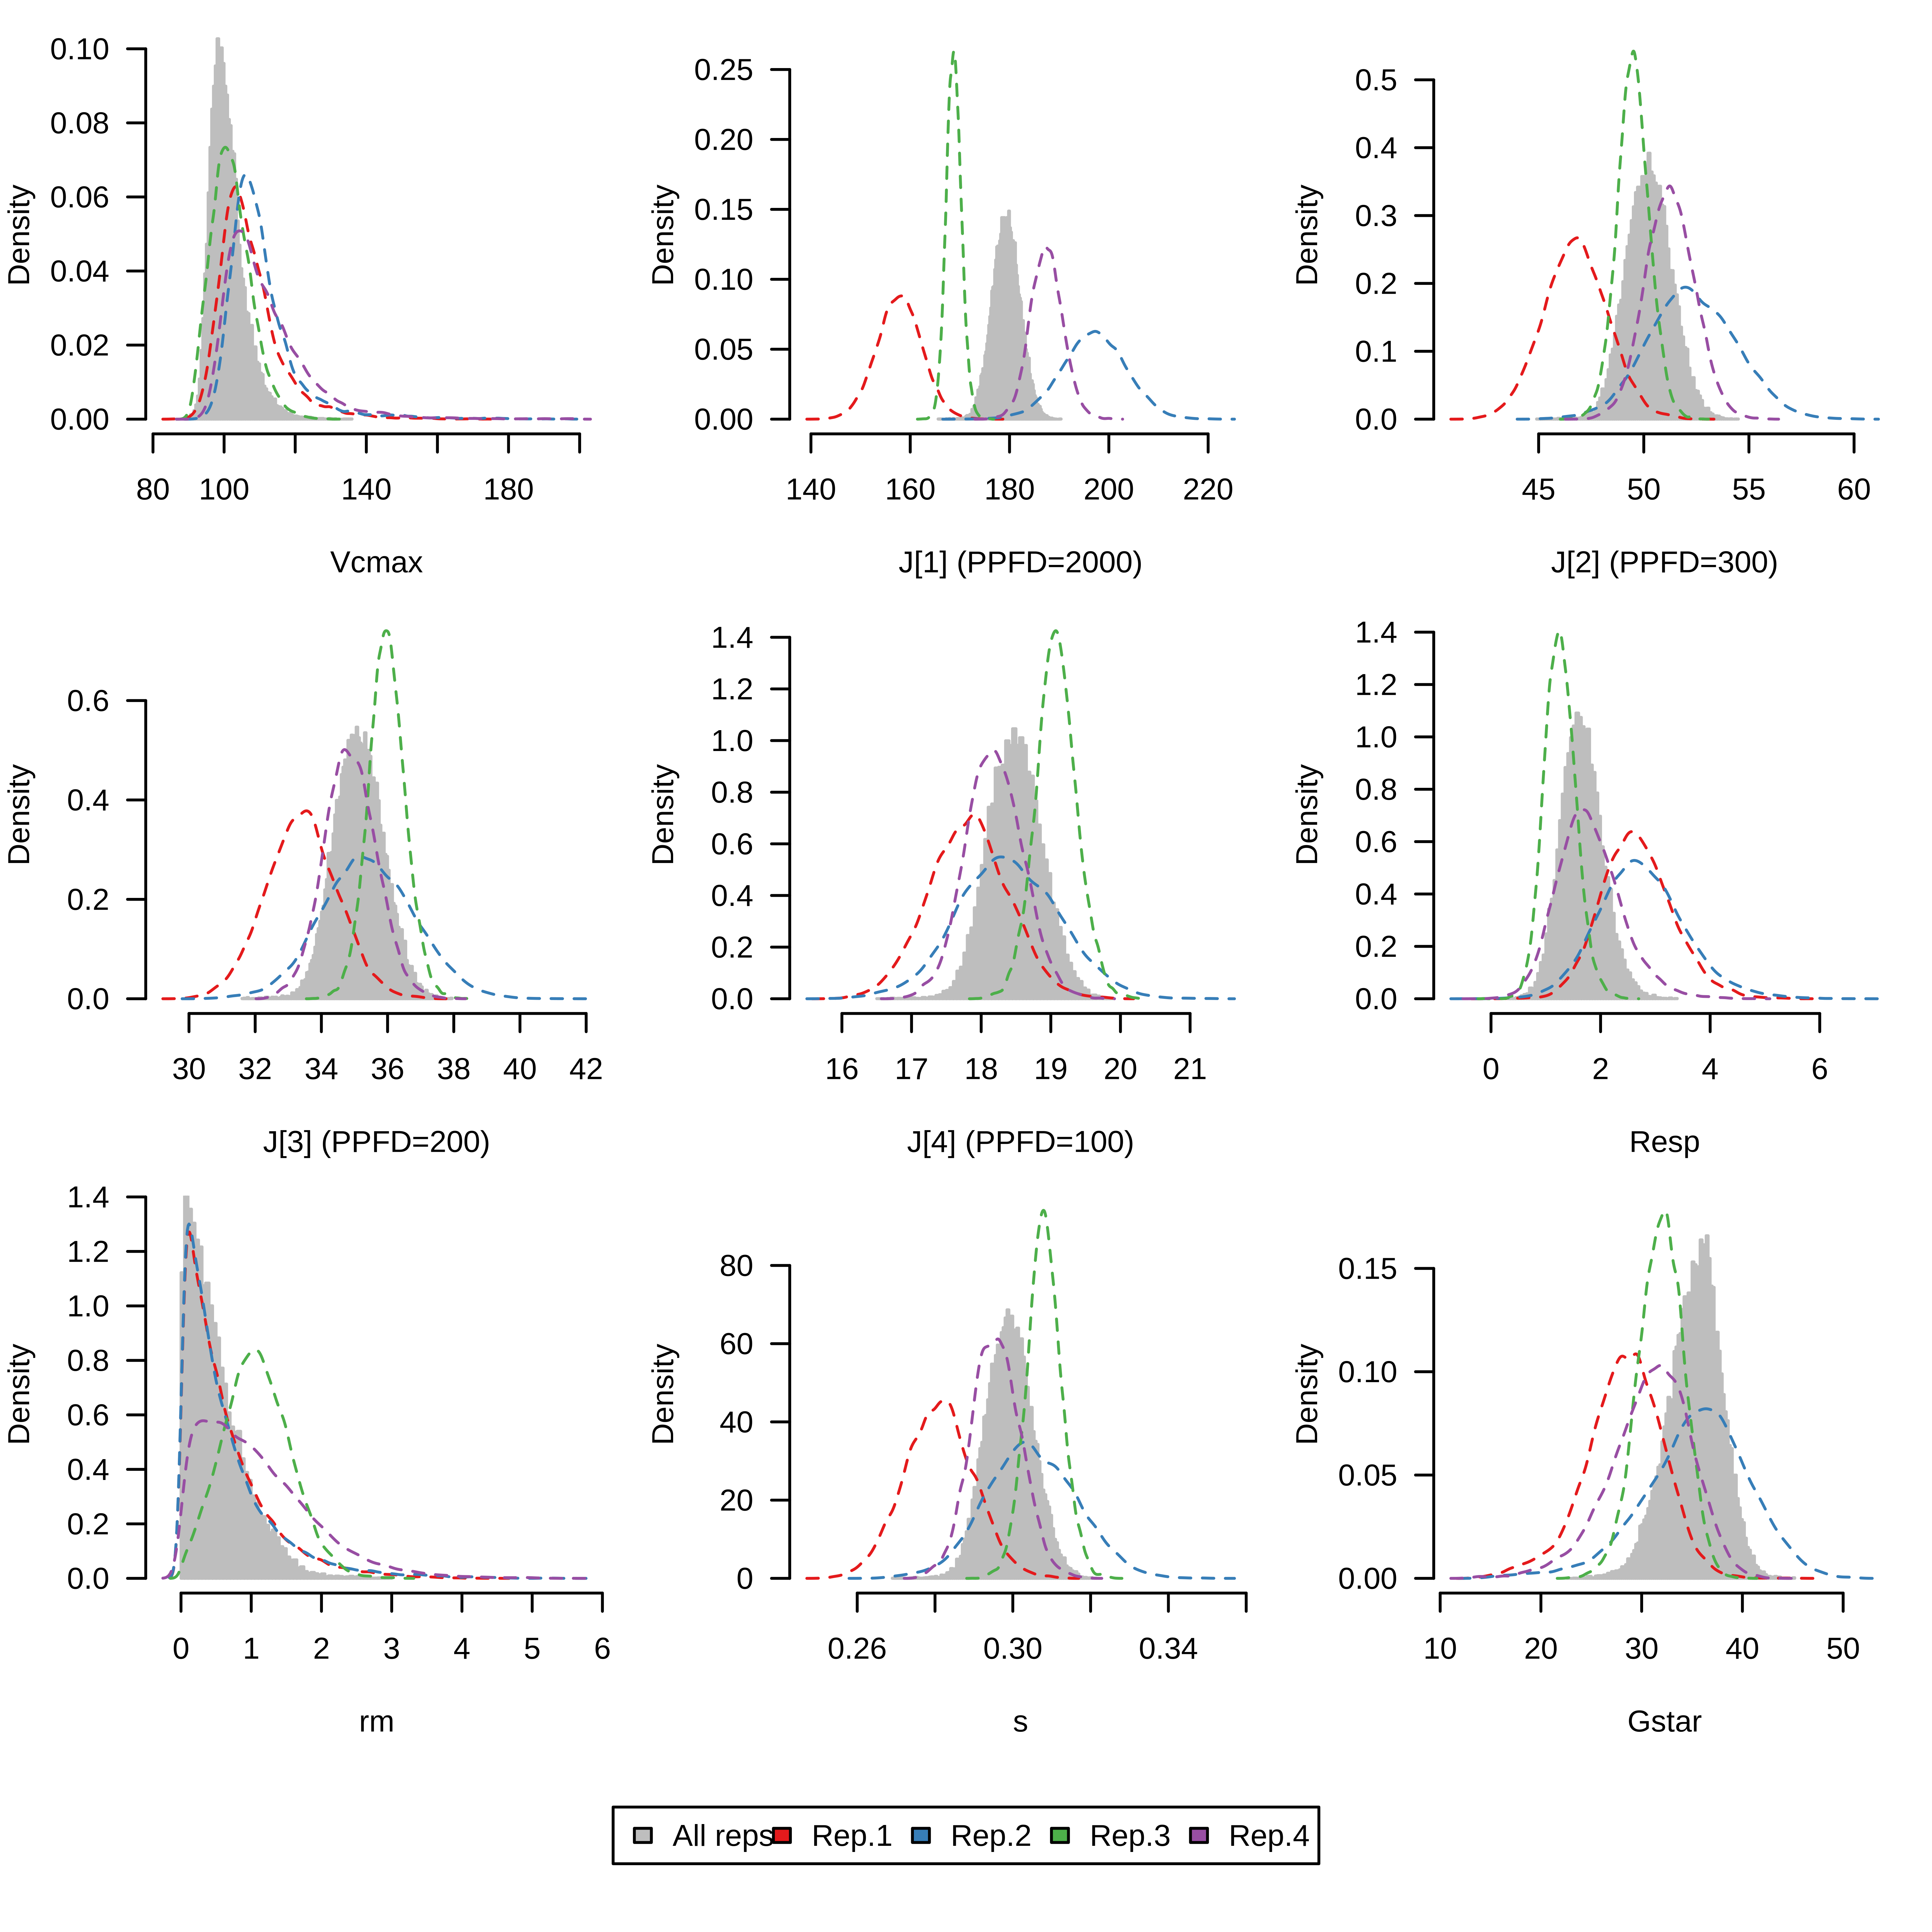

In [ ]:
import subprocess, glob
out = "/content/FvCB-JAGS/output/output_exp0827"
rr = subprocess.run(["apt-get", "install", "-y", "-qq", "poppler-utils"], capture_output=True, text=True)
print("poppler rc =", rr.returncode)
src = f"{out}/rep1/s3.3-posterior Ci response curves-rep1.pdf"
subprocess.run(["pdftoppm", "-png", "-r", "110", "-singlefile", src, "/content/s33_rep1"], check=True)
print("rasterized:", src)
from IPython.display import Image, display
display(Image(filename=f"{out}/s3.1-marginal posterior.png"))

**Author figure caption (s3.1):** marginal posterior distributions of Vcmax, J at each light
level, Resp, rm, s, Gstar — gray histogram: all replications pooled; dashed colored lines: individual
replications. Authors' own saved figure, displayed unmodified.
日本語: 周辺事後分布（灰色ヒストグラム＝全反復プール、色破線＝各反復）。

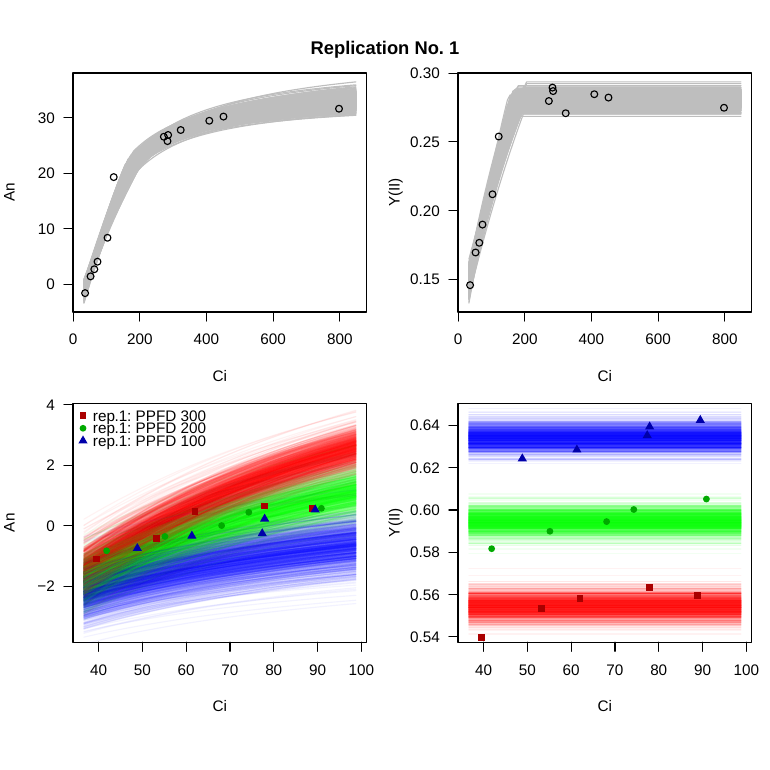

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/s33_rep1.png"))

**Author figure caption (s3.3, replication 1):** posterior predicted response curves (gray/transparent
lines: 1000 posterior samples through the authors' FvCB solution) over the observed An–Ci and
Y(II)–Ci points at saturating and low light. Authors' own saved figure, rasterized from their PDF.
日本語: 1000 個の事後サンプルから描いた予測応答曲線と観測点（rep. 1）。

## Results and interpretation

**What was verified in this run:** the authors' released pipeline executed end to end on their rice
demo data — MCMC convergence (author-printed Rhat values), posterior summaries of Vcmax, J, Resp,
Gstar, rm, s with Km fixed at 428 µbar, and posterior-predicted curves consistent with the observed
An–Ci and Y(II)–Ci points. One-example scope: this does not reproduce the paper's protocol-comparison
results, synthetic-data analysis, or dataset-level statistics; it reproduces the released tool's
demonstration workflow.

**Provenance:** author code and data from `yixiao2/FvCB-JAGS` @ `bb216d78000bda79298ddcd3e6ee60e59254bc14` (GPL-3.0); paper DOI
10.1111/pce.13995; JAGS model `src/fvcb_ayii_ciLL_gm_fixKm_vR.txt` executed unmodified.
All scientific computation ran on the Colab VM.

**Limitations:** R and JAGS versions differ from the authors' 2019 environment (R 3.6.1); MCMC is
seeded (`jags.seed=123`) but posterior draws may vary slightly across JAGS versions/platforms.
The demo CSV rows and the figure style follow the authors' notebook exactly.

日本語: 本実行では著者公開パイプラインをイネのデモデータで末尾まで実行し、Rhat・事後要約・
事後予測曲線を確認しました。1 例の実行であり、論文のプロトコル比較やデータセット全体の結果の
検証ではありません。R/JAGS の版は著者環境（R 3.6.1）と異なります。

## References

- Xiao et al. (2021), *Plant, Cell & Environment* 44(5):1436–1450, DOI 10.1111/pce.13995.
- Author tool: https://github.com/yixiao2/FvCB-JAGS (commit `bb216d78000bda79298ddcd3e6ee60e59254bc14`, GPL-3.0).
- JAGS: http://mcmc-jags.sourceforge.net/ ; R2jags/coda via CRAN.